# 11 · What Actually Lives on Disk?

**NHyDB 0.27.1 notebook series · v1**

The address of a value needs no table – but the value itself needs a carefully built storage container. This notebook opens the box: the files of a database, the append-only file, the commit boundary, what happens after a crash, how the engine checks itself and how backups work.

> **Who is this for?** This notebook starts with a short introduction and continues with runnable examples. **New to NHyDB?** Read from top to bottom – every idea is introduced before it is used. **Already know the basics?** Skip the sections marked 📘 *Background* and jump to the experiments marked ▶. All cells run from top to bottom; optional deep dives are marked ⏩ *Advanced*.

**What you will learn**

* which files belong to a database and what the lock file does
* why the data file only grows (append-only) and how compaction shrinks it on demand
* what the **commit boundary** is – and why an interrupted write never damages committed data
* how `inspect_tail`, `repair_file`, `verify`, `health` and `stats` look into the file
* how to back up, restore and copy a database correctly

**Recommended before:** [02 · From Mathematics to Stored Values](02_from_address_to_data_v1.ipynb).

### Setup

The next cell checks the environment and defines a few small plotting helpers used in
this notebook. It is collapsed because it is not about NHyDB itself – feel free to open
it. Every database in this notebook lives in a temporary folder that is removed at
the end.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.27.1"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})


def plot_path(ax, steps, title=None):
    """'From input to value': boxes coloured by layer A/B/C, connected by arrows.

    ``steps`` is a list of (layer, heading, text) with layer in {"A", "B", "C"}.
    """
    n = len(steps)
    width, gap = 1.0, 0.35
    for i, (layer, head, text) in enumerate(steps):
        x = i * (width + gap)
        ax.add_patch(FancyBboxPatch((x, 0), width, 1, boxstyle="round,pad=0.02,rounding_size=0.06",
                                    facecolor=COLORS[layer + "_light"], edgecolor=COLORS[layer], lw=1.6))
        ax.text(x + width / 2, 0.80, head, ha="center", va="center", fontsize=8.5,
                fontweight="bold", color=COLORS[layer])
        ax.text(x + width / 2, 0.40, text, ha="center", va="center", fontsize=8, color="#111827",
                wrap=True)
        if i < n - 1:
            ax.annotate("", xy=(x + width + gap - 0.02, 0.5), xytext=(x + width + 0.02, 0.5),
                        arrowprops=dict(arrowstyle="-|>", color="#334155", lw=1.3))
    ax.set_xlim(-0.1, n * (width + gap) - gap + 0.1)
    ax.set_ylim(-0.35, 1.15)
    ax.axis("off")
    for j, (layer, name) in enumerate([("A", "A · address space"), ("B", "B · data model"),
                                       ("C", "C · storage engine")]):
        ax.text(j * 1.6, -0.25, "■ " + name, color=COLORS[layer], fontsize=8.5, fontweight="bold")
    if title:
        ax.set_title(title)

import json
import pandas as pd

import re


def short(e):
    # exception text without temporary folder paths
    return type(e).__name__ + ": " + re.sub(r"(/[^\s/]+)+/", "", str(e))


ROLE = {".nhydb": "data (append-only container, not encrypted)",
        ".layout.enc": "layout plan (schema), encrypted",
        ".layout.key": "key for the layout plan – keep it safe!",
        ".lock": "writer lock (empty)"}


def role(filename, base):
    rest = filename[len(base):]
    return ROLE.get(rest or ".nhydb", "backup / other")

Python 3.14.5 · nhydb 0.27.1 · file format 0.16 · matplotlib 3.11.2


## 📘 Background: a container that is only ever appended to

An NHyDB data file has a fixed start – **two superblocks** that say where the last valid commit
ends – followed by **blocks**: dense record blocks, sparse cell blocks, index blocks, system
blocks. New data is always **appended** at the end. Nothing already committed is ever
overwritten in place.

That gives two very useful properties:

* a write that is interrupted can only damage the **end** of the file – never committed data,
* every change is a new state; the old state stays in the file until you **compact** it.

The mathematical number `N` of a cell has nothing to do with its byte position in the file
(layer A vs. layer C). The engine finds the block of a cell through its own in-memory
directory, built when the file is opened.

## 1 · The files of a database

**Question:** What exactly is created on disk?

▶ **Run it:** a small database with 100 measurement records.

In [2]:
PATH = db_path("station.nhydb")
BASE = os.path.basename(PATH)

with nhydb.create(PATH) as db:
    db.create_realm(1, "station")
    db.create_shape(1, 1, "reading", [{"v": 1, "name": "label", "type": "utf8"},
                                      {"v": 2, "name": "value", "type": "f64"}])
    db.create_classic_layout(1, 1, "readings", shape_id=1)
    db.put_dense_batch(1, 1, [[f"v1-{u:03d}", u * 0.5] for u in range(1, 101)], shape_id=1)

files = pd.DataFrame([{"file": f, "bytes": b, "role": role(f, BASE)} for f, b in file_sizes(PATH).items()])
files.set_index("file")

,bytes,role
file,,
station.nhydb,11056,"data (append-only container, not encrypted)"
station.nhydb.layout.enc,1422,"layout plan (schema), encrypted"
station.nhydb.layout.key,160,key for the layout plan – keep it safe!
station.nhydb.lock,0,writer lock (empty)


**One writer at a time.** Opening a database takes an exclusive lock on `<db>.lock` – also for
reading. A second open object (in this or another process) is refused:

In [3]:
with nhydb.open(PATH) as db:
    try:
        nhydb.open(PATH)
    except nhydb.DatabaseLockedError as e:
        print("second open →", short(e))
        locked = True
assert locked
with nhydb.open(PATH) as db:                      # after closing, the lock is free again
    print("reopened after close:", db.get_value(1, 1, 1))

second open → DatabaseLockedError: database is already being written by another process (lock station.nhydb.lock not acquired after 0 ms)
reopened after close: v1-001


## 2 · Append-only: every change is a new state

**Question:** What happens to the file when we overwrite all 100 records again and again?

▶ **Run it:** five rounds of overwriting every record (each round one commit), then deleting
half of the records. After each step we measure the file and check whether the very **first**
value `v1-005` is still physically present in the bytes of the file.

In [4]:
ROUNDS = 5                                            # ▶ Try it: number of overwrite rounds


def contains(path, text):
    with open(path, "rb") as f:
        return text.encode() in f.read()


steps = [{"step": "initial write", "file bytes": os.path.getsize(PATH), "live records": 100,
          "'v1-005' still in file": contains(PATH, "v1-005")}]
with nhydb.open(PATH) as db:
    for r in range(2, ROUNDS + 2):
        db.put_dense_batch(1, 1, [[f"v{r}-{u:03d}", u * 0.5 * r] for u in range(1, 101)], shape_id=1)
        db.commit()
        steps.append({"step": f"overwrite round {r - 1}", "file bytes": os.path.getsize(PATH),
                      "live records": 100, "'v1-005' still in file": contains(PATH, "v1-005")})
    for u in range(1, 101, 2):
        db.delete_record(1, u)
    db.commit()
    steps.append({"step": "delete 50 records", "file bytes": os.path.getsize(PATH), "live records": 50,
                  "'v1-005' still in file": contains(PATH, "v1-005")})
    assert db.get_record(1, 5) is None and db.get_value(1, 6, 1) == f"v{ROUNDS + 1}-006"

result = nhydb.NHyDB.compact_file(PATH, make_backup=False)       # needs the database closed
steps.append({"step": "compact_file", "file bytes": os.path.getsize(PATH), "live records": 50,
              "'v1-005' still in file": contains(PATH, "v1-005")})
growth = pd.DataFrame(steps)
print(f"compaction: {result['before_bytes']:,} → {result['after_bytes']:,} bytes, "
      f"{result['records_written']} records rewritten, verify ok: {result['verify']['ok'] if isinstance(result['verify'], dict) else result['verify']}")
growth

compaction: 22,776 → 12,056 bytes, 50 records rewritten, verify ok: True


,step,file bytes,live records,'v1-005' still in file
0,initial write,11056,100,True
1,overwrite round 1,13000,100,True
2,overwrite round 2,14944,100,True
3,overwrite round 3,16888,100,True
4,overwrite round 4,18832,100,True
5,overwrite round 5,20776,100,True
6,delete 50 records,22776,50,True
7,compact_file,12056,50,False


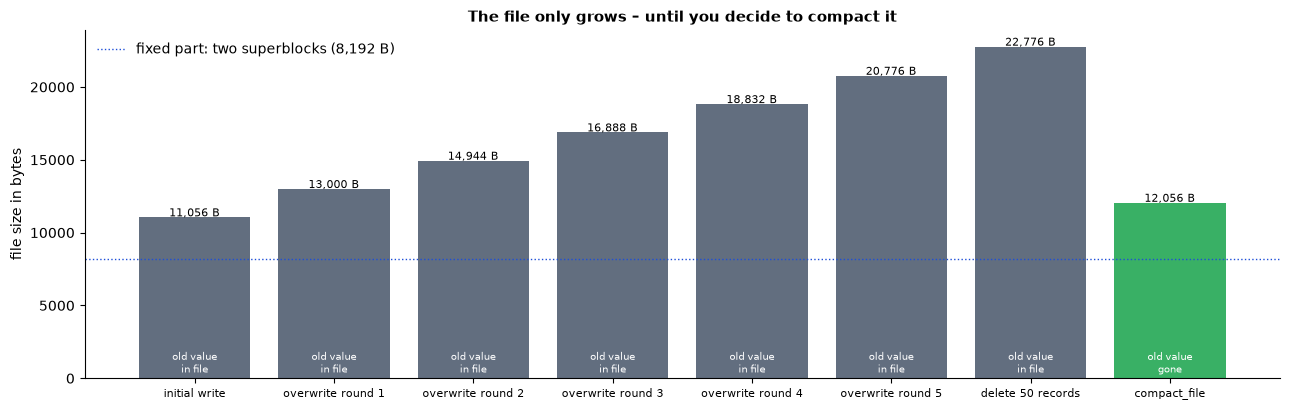

In [5]:
fig, ax = plt.subplots(figsize=(13, 4.2))
base = growth["file bytes"][0]
colors = [COLORS["C"]] * (len(growth) - 1) + [COLORS["ok"]]
bars = ax.bar(range(len(growth)), growth["file bytes"], color=colors, alpha=0.85)
for i, row in growth.iterrows():
    ax.text(i, row["file bytes"] + 60, f"{row['file bytes']:,} B", ha="center", fontsize=8)
    ax.text(i, 400, "old value\nin file" if row["'v1-005' still in file"] else "old value\ngone",
            ha="center", fontsize=7.5, color="white")
ax.axhline(8192, color=COLORS["A"], lw=1, ls=":", label="fixed part: two superblocks (8,192 B)")
ax.set_xticks(range(len(growth)))
ax.set_xticklabels(growth["step"], fontsize=8)
ax.set_ylabel("file size in bytes")
ax.set_title("The file only grows – until you decide to compact it")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

**What happened?**

* Each overwrite round appended about 1 KB: the new versions of the records. Deleting appended
  *tombstones* (markers "this record is gone") – the file grew again although data was removed.
* The first value `v1-005` stayed physically in the file the whole time. Reading always returns
  the **newest** state; older states are simply no longer referenced.
* `compact_file` rewrote only the live state into a fresh container: the file shrank and the old
  versions were gone. NHyDB never compacts automatically – **you** decide when (for example
  after many deletions). **Ah – append-only means: nothing is overwritten, everything is
  decided at the commit.**

## 3 · The commit boundary

**Question:** When is data really safe?

Writes first go to the end of the file. Only `commit()` moves the **commit boundary** (and writes
it into a superblock). When the database is opened, everything **after** the boundary is cut
off. `committed_end` is the boundary, `last_valid_end` the end of everything written so far.

▶ **Run it:** three batches with commit, one without – then the database is closed *without*
committing, just like a crash.

In [6]:
CRASH = db_path("crash.nhydb")
timeline = []
db = nhydb.create(CRASH)
db.create_realm(1, "r")
db.create_shape(1, 1, "s", [{"v": 1, "name": "t", "type": "utf8"}])
db.create_classic_layout(1, 1, "c", shape_id=1)
db.commit()
timeline.append(("schema + commit", db.committed_end, db.last_valid_end))
for k in (1, 2, 3):
    db.put_dense_batch(1, 1, [[f"batch{k}-{u}"] for u in range(1, 101)])
    if k < 3:
        db.commit()
        timeline.append((f"batch {k} + commit", db.committed_end, db.last_valid_end))
    else:
        db.sync()                                     # bytes are in the file, but not committed
        timeline.append((f"batch {k}, NO commit", db.committed_end, db.last_valid_end))
db.close(commit=False)                                # like a crash before the commit

with nhydb.open(CRASH) as db:
    recovered = db.recovered_tail_bytes
    value = db.get_value(1, 5, 1)
print(f"after reopening: {recovered} uncommitted bytes were cut off; record 5 = {value!r}")
assert recovered == timeline[-1][2] - timeline[-1][1] and value == "batch2-5"
pd.DataFrame(timeline, columns=["step", "committed_end", "last_valid_end"])

after reopening: 1440 uncommitted bytes were cut off; record 5 = 'batch2-5'


,step,committed_end,last_valid_end
0,schema + commit,9096,9096
1,batch 1 + commit,10536,10536
2,batch 2 + commit,11976,11976
3,"batch 3, NO commit",11976,13416


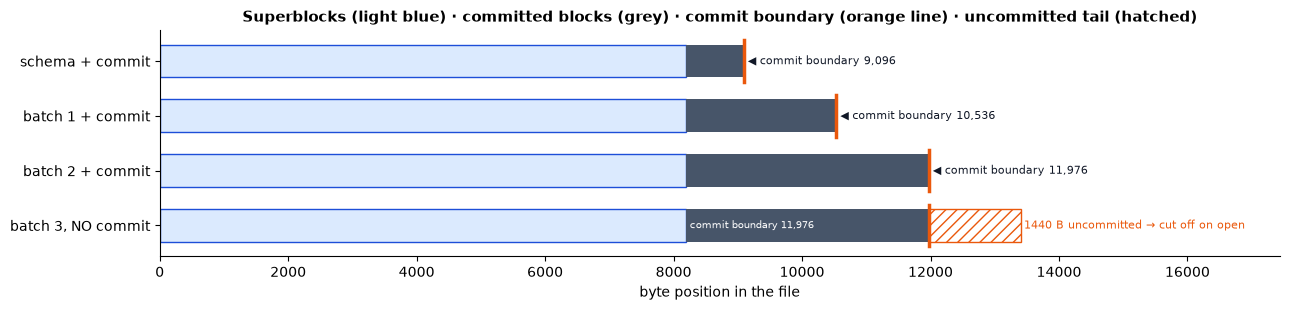

In [7]:
fig, ax = plt.subplots(figsize=(13, 3.2))
for i, (step, committed, written) in enumerate(timeline):
    y = len(timeline) - 1 - i
    ax.barh(y, 8192, color=COLORS["A_light"], edgecolor=COLORS["A"], height=0.6)
    ax.barh(y, committed - 8192, left=8192, color=COLORS["C"], height=0.6)
    if written > committed:
        ax.barh(y, written - committed, left=committed, color="white", edgecolor=COLORS["attention"],
                hatch="///", height=0.6)
        ax.text(written + 40, y, f"{written - committed} B uncommitted → cut off on open",
                va="center", fontsize=8, color=COLORS["attention"])
    ax.plot([committed, committed], [y - 0.38, y + 0.38], color=COLORS["attention"], lw=2.5)
    if written > committed:
        ax.text(8192 + 60, y, f"commit boundary {committed:,}", va="center", fontsize=7.5, color="white")
    else:
        ax.text(committed + 60, y, f"◀ commit boundary {committed:,}", va="center", fontsize=8,
                color="#111827")
ax.set_yticks(range(len(timeline)))
ax.set_yticklabels([t[0] for t in reversed(timeline)])
ax.set_xlabel("byte position in the file")
ax.set_xlim(0, timeline[-1][2] * 1.3)
ax.set_title("Superblocks (light blue) · committed blocks (grey) · commit boundary (orange line) · uncommitted tail (hatched)")
plt.tight_layout()
plt.show()

**What happened?** The third batch reached the file, but the commit boundary still pointed to
the end of batch 2. On the next open the engine cut the tail off – the database is in exactly
the state of the last commit. **Ah – a crash can cost the uncommitted work, never the committed
data.**

## 4 · Damaged files: inspect, repair, refuse

**Question:** What if the end of the file contains garbage, or committed data is missing?

▶ **Run it** – on **copies** only. Case A: an incomplete write at the end (simulated by
appending bytes). Case B: the file was cut short *inside* committed data (for example by a
broken copy).

In [8]:
def copy_db(src, folder):
    os.makedirs(folder, exist_ok=True)
    dst = os.path.join(folder, os.path.basename(src))
    for suffix in ("", ".layout.enc", ".layout.key"):
        shutil.copy2(src + suffix, dst + suffix)
    return dst


# Case A: garbage after the last commit
case_a = copy_db(CRASH, os.path.join(WORKDIR, "case_a"))
with open(case_a, "ab") as f:
    f.write(b"NHBL" + b"\x07" * 40)                  # looks like the start of a block, but is incomplete
tail = nhydb.NHyDB.inspect_tail(case_a)
print("A inspect_tail:", {k: tail[k] for k in ("clean", "trailing_bad_bytes", "error")})
report = nhydb.NHyDB.repair_file(case_a)             # apply=False: only a report
print("A repair_file (report only): clean =", report["clean"])
applied = nhydb.NHyDB.repair_file(case_a, apply=True, make_backup=False)
print("A repair_file(apply=True): applied =", applied["applied"], "→ clean =", nhydb.NHyDB.inspect_tail(case_a)["clean"])
with nhydb.open(case_a) as db:
    assert db.get_value(1, 5, 1) == "batch2-5"
    print("A data after repair:", db.get_value(1, 5, 1))

# Case B: committed data is missing
case_b = copy_db(CRASH, os.path.join(WORKDIR, "case_b"))
with open(case_b, "r+b") as f:
    f.truncate(os.path.getsize(case_b) - 30)
print("\nB inspect_tail:", {k: nhydb.NHyDB.inspect_tail(case_b)[k] for k in ("clean", "last_good_end", "error")})
try:
    nhydb.open(case_b)
    refused = False
except nhydb.CorruptionError as e:
    refused = True
    print("B open →", short(e))
assert refused

A inspect_tail: {'clean': False, 'trailing_bad_bytes': 44, 'error': 'block header magic/version/type invalid'}
A repair_file (report only): clean = False
A repair_file(apply=True): applied = True → clean = True
A data after repair: batch2-5

B inspect_tail: {'clean': False, 'last_good_end': 10536, 'error': 'Block 5: payload incomplete'}
B open → CorruptionError: invalid commit boundary


**What happened?** A damaged **tail** after the commit boundary is harmless: it is reported and
cut off (automatically on open, or explicitly with `repair_file(apply=True)`). Missing
**committed** data is different: the engine refuses to open the file (*fail closed*) instead of
guessing. `repair_file` never invents data – restore such a file from a backup (section 7).

## 5 · Looking inside: blocks, health and verify

**Question:** What is the file made of?

`stats()` reports the storage by block type; `verify` checks the block structure (with
`deep=True` also every payload checksum); `health` runs a list of consistency checks.

In [9]:
with nhydb.open(PATH) as db:
    db.create_index(1, 1, "by_label", "label")
    db.build_indexes()
    db.checkpoint()                                   # writes a CHECKPOINT block and commits
    st = db.stats()
    health = db.health(deep=True)
    verify = db.verify(deep=True)

blocks = st["storage"]["by_block_type"]
print("superblocks:", st["storage"]["superblocks_bytes"], "bytes")
print(pd.DataFrame(blocks).T[["blocks", "bytes", "payload_bytes"]])
print("\nhealth:", health["status"], {c["name"]: c["status"] for c in health["checks"]})
print("verify:", "ok" if verify["ok"] else "errors", f"– {verify['scanned_blocks']} blocks, {verify['error_count']} errors")
assert verify["ok"] and health["status"] == "healthy"

superblocks: 8192 bytes
                 blocks  bytes  payload_bytes
CHECKPOINT            2    376            306
DATA_DENSE           50   3200           1550
SECONDARY_INDEX       1   1336           1298
SYSTEM_R0_U1          2    816            743

health: healthy {'container': 'ok', 'layouts': 'ok', 'spacemap': 'ok', 'layout_routing': 'ok', 'math_layouts': 'ok', 'definitions': 'ok', 'indexes': 'ok', 'checkpoint': 'ok'}
verify: ok – 55 blocks, 0 errors


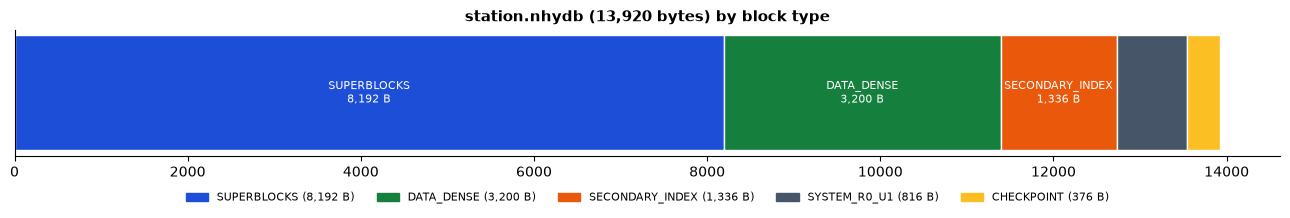

In [10]:
parts = [("SUPERBLOCKS", st["storage"]["superblocks_bytes"])] + sorted(
    ((k, v["bytes"]) for k, v in blocks.items()), key=lambda kv: -kv[1])
palette = {"SUPERBLOCKS": COLORS["A"], "DATA_DENSE": COLORS["B"], "SPARSE_CELLS": "#4ade80",
           "SYSTEM_R0_U1": COLORS["C"], "DB_CONFIG": "#94a3b8", "SECONDARY_INDEX": COLORS["attention"],
           "CHECKPOINT": "#fbbf24"}
fig, ax = plt.subplots(figsize=(13, 2.4))
left = 0
for name, size in parts:
    ax.barh(0, size, left=left, color=palette.get(name, "#cbd5e1"), edgecolor="white")
    if size / sum(s for _, s in parts) > 0.09:
        ax.text(left + size / 2, 0, f"{name}\n{size:,} B", ha="center", va="center", fontsize=8, color="white")
    left += size
handles = [Rectangle((0, 0), 1, 1, color=palette.get(n, "#cbd5e1")) for n, _ in parts]
ax.legend(handles, [f"{n} ({s:,} B)" for n, s in parts], ncol=5, frameon=False, fontsize=8,
          loc="upper center", bbox_to_anchor=(0.5, -0.2))
ax.set_yticks([])
ax.set_title(f"station.nhydb ({left:,} bytes) by block type")
plt.tight_layout()
plt.show()

**What happened?** After compaction the file consists of the two superblocks, a few system
blocks (the identity in R0,u1 – section 6), the dense records, a small index block and the
checkpoint. The 50 remaining records sit at every second `u` (the odd ones were deleted), so
they are written as 50 small dense segments – a contiguous range would need far fewer blocks. `health` reports `healthy` because a checkpoint exists and all checks pass.

## 6 · The identity of a database: R0,u1

Every database stores its identity in a reserved system space, the cells `(0, 1, v)`:
database id, file names, schema generation and hash, creation time, encryption scheme and the
fixed constants. Realm 0 is not a Dynadron realm for user data – it is the engine's own
nameplate. Notebook 12 shows how it binds the data file to its layout plan.

In [11]:
LABELS = {1: "database id (UUID)", 2: "original file name", 3: "layout plan file", 4: "key file name",
          5: "plan generation", 6: "SHA-256 of the schema", 7: "created (ns)", 8: "encryption scheme",
          9: "fixed constants"}
with nhydb.open(PATH) as db:
    meta = db.get_system_metadata()
system = pd.DataFrame([{"cell": f"R0,u1,v{v}", "meaning": LABELS[v],
                        "value": str(meta["cells"][str(v)])[:70]} for v in range(1, 10)])
system.set_index("cell")

,meaning,value
cell,,
"R0,u1,v1",database id (UUID),52c1976f-206c-48d5-9895-e91559afb415
"R0,u1,v2",original file name,station.nhydb
"R0,u1,v3",layout plan file,station.nhydb.layout.enc
"R0,u1,v4",key file name,station.nhydb.layout.key
"R0,u1,v5",plan generation,2
"R0,u1,v6",SHA-256 of the schema,87a3c3d013771a8bda1431cebfd92ba73b0eaaf93122e7...
"R0,u1,v7",created (ns),1792413048727447000
"R0,u1,v8",encryption scheme,AES-256-GCM + HMAC-SHA256
"R0,u1,v9",fixed constants,"{'lane_NL': 0, 'lane_NR': 1, 'realm_span': 100..."


## 7 · Backup, restore and copies

**Rules** (Cookbook section 21):

* back up **all three files** (`.nhydb`, `.layout.enc`, `.layout.key`) while the database is
  **closed**;
* restore under the **same file name** (another folder is fine) – the file name is part of the
  identity;
* to get a copy under a new name, use `compact_file(path, output=new_path)`.

In [12]:
backup = copy_db(PATH, os.path.join(WORKDIR, "backup"))              # 1. backup (database closed)
restored = copy_db(backup, os.path.join(WORKDIR, "restored"))        # 2. restore elsewhere
with nhydb.open(restored) as db:
    print("restored copy opens:", db.get_value(1, 6, 1))

renamed = os.path.join(os.path.dirname(restored), "renamed.nhydb")   # 3. a renamed data file ...
os.rename(restored, renamed)
try:
    nhydb.open(renamed, layout_path=restored + ".layout.enc", key_path=restored + ".layout.key")
    rejected = False
except nhydb.CorruptionError as e:
    rejected = True
    print("renamed file →", short(e))
assert rejected

copy = os.path.join(WORKDIR, "copies", "station_copy.nhydb")        # 4. ... the right way
os.makedirs(os.path.dirname(copy), exist_ok=True)
nhydb.NHyDB.compact_file(PATH, output=copy)
with nhydb.open(copy) as db:
    meta_copy = db.get_system_metadata()["cells"]
    print("copy under new name opens:", db.get_value(1, 6, 1), "| own id:", meta_copy["1"] != meta["cells"]["1"])
print(sorted(os.listdir(os.path.dirname(copy))))

restored copy opens: v6-006
renamed file → CorruptionError: DB file name does not match R0,u1


copy under new name opens: v6-006 | own id: True
['station_copy.nhydb', 'station_copy.nhydb.layout.enc', 'station_copy.nhydb.layout.key', 'station_copy.nhydb.lock']


**What happened?** The restored copy opened because the names still match the identity stored
in R0,u1. The renamed file was rejected: the name in the file and the name on disk differ. The
compacted copy is a new database with its **own** id and its own plan and key files.

## Your turn

**Task:** how many bytes does one overwrite round of 100 records cost on average? Compute it from
the `growth` table of section 2 and compare it with the size of the compacted file.

In [13]:
rounds = growth[growth["step"].str.startswith("overwrite")]
per_round = rounds["file bytes"].diff().dropna().mean() if len(rounds) > 1 else rounds["file bytes"].iloc[0] - growth["file bytes"][0]
print(f"one overwrite round ≈ {per_round:,.0f} bytes  (≈ {per_round / 100:.1f} bytes per record)")
print(f"compacted file: {growth['file bytes'].iloc[-1]:,} bytes for 50 live records")
assert per_round > 0

one overwrite round ≈ 1,944 bytes  (≈ 19.4 bytes per record)
compacted file: 12,056 bytes for 50 live records


## ⏩ Advanced: waiting for the lock, durability

A second process can **wait** for the lock instead of failing (`lock_timeout_ms`). The durability
mode decides how hard a commit syncs: `"fsync"` (default) or `"full"` (on macOS additionally
flushes the drive cache).

In [14]:
import subprocess
import textwrap

holder = textwrap.dedent('''
    import sys, time, nhydb
    db = nhydb.open(sys.argv[1])
    print("locked", flush=True)
    time.sleep(1.0)
    db.close()
''')
proc = subprocess.Popen([sys.executable, "-c", holder, PATH], stdout=subprocess.PIPE, text=True)
assert proc.stdout.readline().strip() == "locked"
try:
    nhydb.open(PATH)
except nhydb.DatabaseLockedError:
    print("other process holds the lock → DatabaseLockedError")
db = nhydb.open(PATH, lock_timeout_ms=10_000)          # waits until the other process closes
print("opened after waiting; durability =", db.durability)
db.close()
proc.wait(timeout=30)
proc.stdout.close()

other process holds the lock → DatabaseLockedError


opened after waiting; durability = fsync


## Summary

* A database is three files that belong together (+ the lock file); only the layout plan is encrypted.
* The data file is append-only: overwrites and deletions add new states; `compact_file` removes old ones on demand.
* Only committed data counts: an uncommitted or damaged tail is cut off, missing committed data is refused.
* `stats`, `verify`, `health`, `inspect_tail` and `repair_file` look into the container; R0,u1 holds its identity.
* Back up all three files while closed; restore under the same name; copy with `compact_file(output=…)`.

## Where to go next

* [12 · One Layout Plan, Two Views](12_encrypted_layout_and_key_v1.ipynb) – how plan and key protect the schema.
* [13 · Benchmark Lab](13_benchmark_lab_v1.ipynb) – what commits and durability cost.

**Cookbook sections:** 5 (Commit, sync, close), 20 (Maintenance), 21 (Files, backup), 22 (Locks), 23 (R0,u1) in the [NHyDB Python Cookbook](https://github.com/nhydb/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [15]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
